In [167]:
# Rountines to plot and visualize ARC specified FAR3D output datafiles 
# Written by Arunav Kumar,19/10/2024  
# arunavk@mit.edu 
import sys 
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from iota_Analysis_TK import *
import os

In [ ]:
#omegar,iflr are only considered when iflr_on=1 (thermal ion FLR damping effects )
#omgcya = cyclotron FR
#omcy = cyclotron frequency of the fast particles (normalized to the Alfven time) 
#omcyb = bounce frequency of the helically trapped energetic particles (normalized Alfven time)



Acceptable Convergence
-0.0730813 22.25869209764841 0.16 9.309928649524107 ['11'] 11.5 Va = 9132777.110489966
SPARC $T_{f}:$22 keV/ $\beta_{0f}$:0.021/ $f$: 9 kHz/ 
$\gamma$:-0.0730813$\tau_{A}^{-1}$
Dominant Mode (n/m): R  8/11 Coupled (n/m): R  9/11 R 14/11


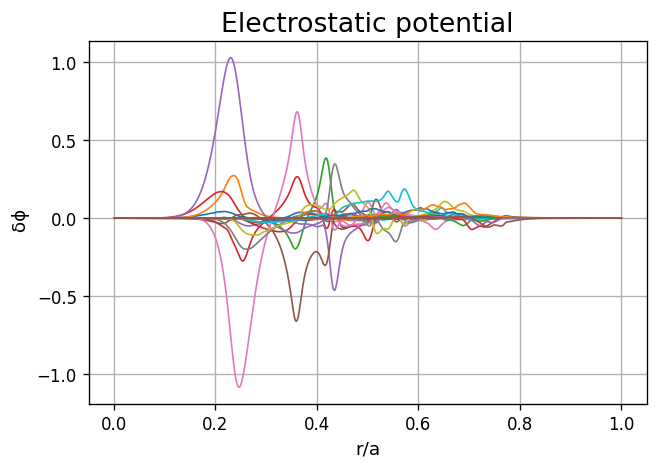

In [375]:
fp='ARC2/farprt'
profile_data='ARC2/ARC_V2B.txt'

#Give the maximum number of poloidal modes
num_poloidal = 21

df = pd.read_csv("ARC2/br_0000", sep="\t")
r = df["r"]
df = df.drop("r",axis=1)

gr, freq, toroidal_coupl = get_main_data(fp)
frequency, energy, beta, kev , B, Va, q = plasma_parameters(fp,profile_data,abs(float(freq)))
#dominant_mode, radial_pos, dominant_mode_2, radial_pos_2,dominant_mode_3,radial_pos_3, alfmode,x1,x2,width = get_values(df)

print(gr,energy,kev,frequency,toroidal_coupl, B, 'Va =',Va)
print(r"SPARC $T_{f}:$" + f"{round(int(energy))} keV/ "+ r"$\beta_{0f}$:"+f"{beta}/ $f$: {round(frequency)} kHz/ ")
print(r"$\gamma$:"+f"{gr}"+r"$\tau_{A}^{-1}$")

plt.figure(figsize=(6,4), dpi=120)
plt.plot(np.array(r),np.array(df)[:,:],'-',linewidth=1)
plt.xlabel("r/a")
plt.ylabel(' δϕ')
print('Dominant Mode (n/m):',dominant_mode,'Coupled (n/m):',dominant_mode_2,dominant_mode_3)
plt.title('Electrostatic potential', fontsize=16, color='black')
#plt.ylabel(r"$br$")
plt.rcParams['axes.labelsize'] = 11
plt.grid(True)
plt.show()

In [305]:
#np.array(df)[:,:].shape

Dominant Mode (n/m): R  8/11 Coupled (n/m): R  9/11 R 14/11


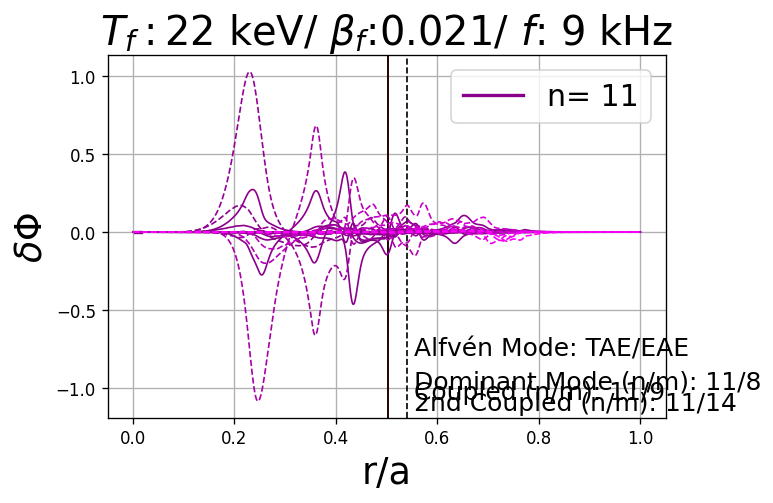

In [367]:
plot_eigenfunctions(dominant_mode,dominant_mode_2,dominant_mode_3,alfmode,radial_pos,radial_pos_2,radial_pos_3,
                    df,r,energy,beta,frequency,'',toroidal_coupl, 12)
dm = change_modes_order(dominant_mode)
dm2 = change_modes_order(dominant_mode_2)
print('Dominant Mode (n/m):',dominant_mode,'Coupled (n/m):',dominant_mode_2,dominant_mode_3)


In [4]:
#From farprt and profiles.dat obtains the relevant plasma characteristics
def check_convergence(list_modes):
    val_0 = list_modes[0]
    chek = True

    #Compare items in list
    for val in list_modes:
        if val_0 != val:
            chek = False
            break

    return chek
def get_number_line(line):
    #array to save the number values in array
    value = []
    for char in line:
        if char.isdigit() or char == ".":
            value.append(char)

    new_value = "".join(value)
    new_value = float(new_value)

    return new_value

def change_modes_order(mode):
    
    modes = mode.split("/")
    n = modes[1]

    if "-" in modes[0]:
        m = modes[0].split("-") 
        m = m[-1]

    elif "  " in modes[0]: 
        m = modes[0].split("  ") 
        m = m[-1]

    else:
        m = modes[0].split(" ") 
        m = m[-1]

    inverted_mode = f"{n}/{m}"

    return inverted_mode


def plasma_parameters(fp,profile,frec):
    #Read farprt
    farprt_data = open(fp)
    nfarprt_data = farprt_data.readlines()
    
    #profile, exist = find_profiles(directory)
    
    #read external profiles
    data = open(profile)
    ndata = data.readlines()
    
    #constants
    mi = 1.67e-27
    mu_0 = 1.25664e-06
    e = 1.602e-19
    
    #EP energy
    tline = [idx for idx,line in enumerate(nfarprt_data) if 'cvfp:' in line][0] + 1
    cvfp = nfarprt_data[tline].split(",")
    cvfp = float(cvfp[0])
    
    #EP beta
    tline = [idx for idx,line in enumerate(nfarprt_data) if 'bet0_f' in line][0] + 1
    beta = nfarprt_data[tline].split("\t")
    beta = float(beta[0])
    
    #Magnetic Field
    tline = [idx for idx,line in enumerate(ndata) if 'Vacuum' in line][0] + 1
    B = ndata[tline]
    B = get_number_line(B)
    
    #Major Radius
    tline = [idx for idx,line in enumerate(ndata) if 'Geometric Center' in line][0] + 1
    R = ndata[tline]
    R = get_number_line(R)
    
    #Main Ion species mass/proton
    tline = [idx for idx,line in enumerate(ndata) if 'Main Ion' in line][0] + 1
    M = ndata[tline]
    M = get_number_line(M)
    
    #Density and safety factor
    tline = [idx for idx,line in enumerate(ndata) if 'Rho' in line][0] + 1
    full_line = ndata[tline].split("\t")
    full_line = full_line[0].split(" ")
    q = float(full_line[1])
    ni = float(full_line[3])
    ni = ni*10**(20)
    
    #Alfvén speed
    Va = (B)/np.sqrt(M*mu_0*mi*ni)

    #Frecuency
    f = (frec*Va)/(2*np.pi*R*1000*q)
    #Energy
    energy = mi*(cvfp*Va)**2/(e*1000)
    
    return f, energy, beta, cvfp, B, Va, q

In [5]:
#From farprt obtains frequency and growth rate, and checks convergence of the simulation
def get_main_data(f):
    data = open(f)
    ndata = data.readlines()
    line_diference = 4
    toroidal_couplings = []
    gamma = []

    tline = [idx for idx,line in enumerate(ndata) if 'n       Avg. gam:         Avg. om_r:' in line][0] + 1
    n, grwth, omega = ndata[tline].split()
    toroidal_couplings.append(n)

    if grwth == "NaN":
        grwth, omega = 0,-1000
    else: 
        grwth, omega = float(grwth), float(omega)

    gamma.append(grwth)
    
    try:
        for i in range(1,10):
            tline = [idx for idx,line in enumerate(ndata) if 'n       Avg. gam:         Avg. om_r:' in line][0] + 1 + (line_diference*i)
            n, grwth1, omega1 = ndata[tline].split()
            toroidal_couplings.append(n)
        
            if grwth1 == "NaN" or grwth1 == "nan":
                grwth1, omega1 = 0,-1000
            else:
                grwth1, omega1 = float(grwth1), float(omega1)

            gamma.append(grwth1)
                
            if grwth1 >= grwth:
                grwth = grwth1
                omega = omega1

    except Exception as e:
        x = 0

    chek = check_convergence(gamma)      

    if chek:
        print("Acceptable Convergence")
    else:
        print("Non-convergence Simulation")

    return grwth, omega, toroidal_couplings


array([22.09865413, 22.09172901, 22.06687532, 22.01337555, 21.92043343,
       21.77987048, 21.58753862, 21.34411108, 21.05270324, 20.71111938,
       20.32313049, 19.90518728, 19.48303808, 19.07180206, 18.64036835,
       18.21122196, 17.81522955, 17.4415087 , 17.07098974, 16.72446406,
       16.40775503, 16.10569771, 15.80968684, 15.52027936, 15.24441073,
       14.98744608, 14.74785061, 14.50735678, 14.23252639, 13.9176529 ,
       13.59181405, 13.29269723, 13.0451952 , 12.84848719, 12.67369075,
       12.47615224, 12.23220623, 11.95178523, 11.66734308, 11.40871036,
       11.18802376, 11.00025583, 10.82432734, 10.62125811, 10.38698168,
       10.14622497,  9.91483869,  9.69459421,  9.48474071,  9.28199268,
        9.0845838 ,  8.89509965,  8.71323952,  8.53716202,  8.36656864,
        8.20096327,  8.03861987,  7.8785275 ,  7.72191676,  7.57041038,
        7.42407182,  7.28212337,  7.14379013,  7.00851688,  6.87611615,
        6.74710271,  6.6218799 ,  6.50025301,  6.38190174,  6.26

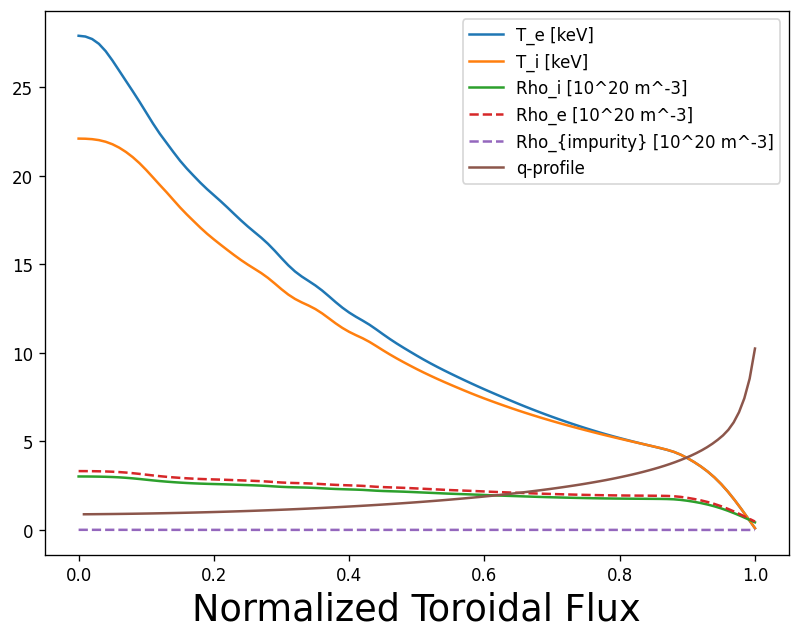

In [212]:
profile_data='ARC2/ARC_V2B.txt'

rho_values, q_values, Beam_Ion_Density, Ion_Density, Electron_Density, Impurity_Density = ([] for _ in range(6))
Beam_Ion_Effective_Temp, Ion_Temp, Electron_Temp = ([] for _ in range(3))
Beam_Pressure, Thermal_Pressure, Equil_Pressure, Tor_Rot, Pol_Rot =  ([] for _ in range(5))

#for line in profile_data:
#    print(profile_data.readline())
with open(profile_data, 'r') as file:
    lines = file.readlines()[18:]

for line in lines:
    if line.strip(): 
        parts = line.split()
        rho_values.append(float(parts[0]))
        q_values.append(float(parts[1]))
        Beam_Ion_Density.append(float(parts[3]))
        Ion_Density.append(float(parts[3]))
        Electron_Density.append(float(parts[4]))
        Impurity_Density.append(float(parts[5]))
        Beam_Ion_Effective_Temp.append(float(parts[6]))
        Ion_Temp.append(float(parts[7])) 
        Electron_Temp.append(float(parts[8]))
        Beam_Pressure.append(float(parts[10]))
        Thermal_Pressure.append(float(parts[10]))
        Equil_Pressure.append(float(parts[11]))
        Tor_Rot.append(float(parts[12]))
        Pol_Rot.append(float(parts[13]))
plt.figure(figsize=(8, 6),dpi=120)
plt.plot(rho_values, np.array(Electron_Temp),'-', label='T_e [keV]' )
plt.plot(rho_values, np.array(Ion_Temp),'-', label='T_i [keV]')
plt.plot(rho_values, np.array(Ion_Density),'-', label='Rho_i [10^20 m^-3]')
plt.plot(rho_values, np.array(Electron_Density),'--', label='Rho_e [10^20 m^-3]' )
plt.plot(rho_values, np.array(Impurity_Density),'--', label='Rho_{impurity} [10^20 m^-3]' )
plt.plot(abs(b.phi[1:]/b.phi[-1]),1/abs(b.iota),'-', label='q-profile')
plt.xlabel('Normalized Toroidal Flux')
plt.legend()
#Beam_Pressure=0*np.array(Beam_Pressure)
#Beam_Ion_Density= 0.0*np.array(Beam_Ion_Density)
#Thermal_Pressure=th_press
#Tor_Rot=toroidal_rot
#Beam_Ion_Effective_Temp=0.0*np.array(Ion_Temp)
#plt.plot(rho_values, np.array(Beam_Ion_Effective_Temp),'.', label='T_i(eff)' )
#Impurity_Density = imp_rho
#Tor_Rot=0*np.array(Tor_Rot)
#Ion_Density=I_denisty
#Electron_Density=Elec_rho
#Electron_Temp= Elc_tem #Elec_rho*2.5 #1.2*np.array(Electron_Temp)-0.65
#Ion_Temp= Ion_tem  #Elec_temperature
np.array(Ion_Temp)

In [ ]:
with open(profile_data, 'a') as file:
    # Write the modified data
    for i in range(len(rho_values)):
        file.write(f"{rho_values[i]} {q_values[i]} {Beam_Ion_Density[i]} {Ion_Density[i]} {Electron_Density[i]} {Impurity_Density[i]} {Beam_Ion_Effective_Temp[i]} {Ion_Temp[i]} {Electron_Temp[i]} {Beam_Pressure[i]} {Thermal_Pressure[i]} {Equil_Pressure[i]} {Tor_Rot[i]} {Pol_Rot[i]}\n")

In [ ]:
#profile_data='SPARC/leon_v2.txt'
profile_data='DIIID/Data.txt'

rho_values, q_values, Beam_Ion_Density, Ion_Density, Electron_Density, Impurity_Density = ([] for _ in range(6))
Beam_Ion_Effective_Temp, Ion_Temp, Electron_Temp = ([] for _ in range(3))
Beam_Pressure, Thermal_Pressure, Equil_Pressure, Tor_Rot, Pol_Rot =  ([] for _ in range(5))
#for line in profile_data:
#    print(profile_data.readline())
with open(profile_data, 'r') as file:
    lines = file.readlines()[18:]

for line in lines:
    if line.strip(): 
        parts = line.split()
        rho_values.append(float(parts[0]))
        q_values.append(float(parts[1]))
        Beam_Ion_Density.append(float(parts[3]))
        Ion_Density.append(float(parts[3]))
        Electron_Density.append(float(parts[4]))
        Impurity_Density.append(float(parts[5]))
        Beam_Ion_Effective_Temp.append(float(parts[6]))
        Ion_Temp.append(float(parts[7])) 
        Electron_Temp.append(float(parts[8]))
        Beam_Pressure.append(float(parts[10]))
        Thermal_Pressure.append(float(parts[10]))
        Equil_Pressure.append(float(parts[11]))
        Tor_Rot.append(float(parts[12]))
        Pol_Rot.append(float(parts[13]))
plt.plot(rho_values, 1*np.array(Ion_Temp),'.', label='Rho_i')
plt.plot(rho_values, 1*np.array(Electron_Temp),'--', label='Rho_e' )
plt.legend()

print(Thermal_Pressure)

In [ ]:
# Trimming the y_values array to remove the trailing [0.1, 0.1, 0.1]
from scipy.interpolate import interp1d
y_values_trimmed = np.array([22.27972   , 22.24608   , 22.177118  , 22.07403   , 21.93919   ,
       21.77574 , 21.58756   , 21.37875   , 21.152712  , 20.91258   ,
       20.66104   , 20.40027   , 20.132141  , 19.857962  , 19.57865   ,
       19.294641  , 19.00594   , 18.71277   , 18.41531   , 18.1136    ,
       17.80733   , 17.493631  , 17.163689  , 16.826279  , 16.5171    ,
       16.22629   , 15.89778   , 15.576349  , 15.28827   , 15.00387   ,
       14.730559  , 14.44382   , 14.167231  , 13.88613   , 13.61101   ,
       13.33423   , 13.06631   , 12.80693   , 12.538441  , 12.26721   ,
       12.05016   , 11.83921   , 11.6394005 , 11.43548   , 11.25218   ,
       11.05261   , 10.87735   , 10.69591   , 10.52912   , 10.37236   ,
       10.23654   , 10.10826   ,  9.924911  ,  9.777525  ,  9.564474  ,
        9.350457  ,  9.13916   ,  8.930954  ,  8.726175  ,  8.526544  ,
        8.332264  ,  8.15521   ,  7.985752  ,  7.8233953 ,  7.669682  ,
        7.5156374 ,  7.3646326 ,  7.218118  ,  7.0769877 ,  6.9349637 ,
        6.7881317 ,  6.6498723 ,  6.514396  ,  6.3781033 ,  6.24888   ,
        6.11687   ,  5.987391  ,  5.864583  ,  5.743899  ,  5.625956  ,
        5.510672  ,  5.39972   ,  5.289845  ,  5.181821  ,  5.080915  ,
        4.979614  ,  4.882111  ,  4.78831   ,  4.699402  ,  4.614818  ,
        4.534377  ,  4.453238  ,  4.377272  ,  4.300335  ,  4.266113  ,
        4.024698  ,  2.795813  ,  0.9906306 ,  0.4035365 ,  0.31282252, 0.021282252])

x_values_new = np.linspace(0.0, 1.0, 101)
x_values_trimmed = np.linspace(0, 1, len(y_values_trimmed))
interpolation_function_trimmed = interp1d(x_values_trimmed, y_values_trimmed, kind='quadratic', fill_value="interpolate")
y_values_extrapolated_trimmed = interpolation_function_trimmed(x_values_new)

plt.figure(figsize=(10, 6))
plt.plot(x_values_trimmed, y_values_trimmed, '--', label='Original Data')
plt.plot(x_values_new, y_values_extrapolated_trimmed, '.', label='Extrapolated Data')
plt.legend()
plt.xlabel('X values')
plt.ylabel('Y values')
plt.title('Extrapolation of Trimmed Data')
plt.grid(True)
plt.show()

y_values_extrapolated_trimmed

In [7]:
def get_values(data_frame):
    #Obtain Eigenmode with maximum amplitude
    data = data_frame.abs()
    df_desc = data.describe()
    s_max = df_desc.loc["max"]
    
    #Column name for the mode with maximum amplitude
    dominant_mode = s_max[s_max.isin([max(df_desc.loc["max"])])].index[0] 
    radial_pos = np.argmax(data[dominant_mode].values)
    sol = dominant_mode[0]

    #Width of the maximum mode
    max_df = data_frame[dominant_mode]
    y1,x1,y2,x2,width = dominant_mode_width(max_df)
    
    #Delete dominant mode from data_frame
    data = data.drop(dominant_mode,axis=1)
    for col in data.columns:
        if sol not in col:
            data = data.drop(col,axis=1)
       
    #treshold = 1
    #while(treshold <= 0.08):
    df_desc_sec = data.describe()
    s_max = df_desc_sec.loc["max"]
    dominant_mode_2 = s_max[s_max.isin([ max(df_desc_sec.loc["max"])])].index[0]
    radial_pos_2 = np.argmax(data[dominant_mode_2].values)
    treshold = abs(radial_pos - radial_pos_2)/1000
    data = data.drop(dominant_mode_2,axis=1)  
    
    n1 = dominant_mode.split("/")
    n2 = dominant_mode_2.split("/")
    
    try:
        m1 = n1[0].split("-") 
        m2 = n2[0].split("-")
        m_1,m_2 = int(m1[-1]),int(m2[-1])

    except Exception as e: 
        m1 = n1[0].split(" ") 
        m2 = n2[0].split(" ")
        m_1,m_2 = int(m1[-1]),int(m2[-1])

    except Exception as error:
        m1 = n1[0].split("  ") 
        m2 = n2[0].split("  ")
        m_1,m_2 = int(m1[-1]),int(m2[-1])

    n_1,n_2 = int(n1[1]),int(n2[1])
    
    try:
        if(n_1 == n_2):
            df_desc_3 = data.describe()
            s_max = df_desc_3.loc["max"]
            dominant_mode_3 = s_max[s_max.isin([ max(df_desc_3.loc["max"])])].index[0]
            radial_pos_3 = np.argmax(data[dominant_mode_3].values)
            treshold = abs(radial_pos - radial_pos_3)/1000
            data = data.drop(dominant_mode_3,axis=1)
        else:
            dominant_mode_3 = "--"
            radial_pos_3 = "--"
    except Exception as e:
        dominant_mode_3 = "--"
        radial_pos_3 = "--"
    
    if(n_1 != n_2):
        alfmode = "HAE"
    if(n_1 == n_2):
        if(m_1 + 1 == m_2 or m_1 - 1 == m_2):
            alfmode = "TAE/EAE"
    
    return dominant_mode, radial_pos, dominant_mode_2, radial_pos_2,dominant_mode_3, radial_pos_3, alfmode, x1, x2, width


def dominant_mode_width(max_dataframe):
    max_dataframe = pd.DataFrame(max_dataframe)
    #Defines radius column and add it to the dataframe
    radius = np.linspace(0,1000,1001)
    max_dataframe['Radius'] = radius
    max_mode = abs(max_dataframe)
    name_column = max_dataframe.columns
    
    max_mode = max_mode.loc[max_mode[name_column[0]] >= max(max_mode[name_column[0]])/3]
    
    #Obtain the points for the width for the max eigenfunction
    x1 = max_mode["Radius"].iloc[0]
    y1 = max_mode[name_column[0]].iloc[0]
    
    x2 = max_mode["Radius"].iloc[-1]
    y2 = max_mode[name_column[0]].iloc[-1]

    width = x2-x1
    
    return y1,x1,y2,x2,width

In [8]:
from PIL import Image
import matplotlib.colors as mc
def get_colors_dict(n):
    n = int(n)
    
    d =  {
	1: {
            'colfam': "black",
            'colors': ['black','silver'] 
        },
	2: {
            'colfam': 'navy',
            'colors': ["navy","royalblue"]             
        },
    3: {
            'colfam': "darkslategrey",
            'colors': ["darkslategrey","darkturquoise"]             
        },
	4: {
            'colfam': "brown",
            'colors': ["saddlebrown","sandybrown"] 
        },
        
    5: {
            'colfam': 'blue',
            'colors': ['navy','lightskyblue']
        },
    6: {
            'colfam': 'darkturquoise',
            'colors': ['darkcyan','cyan']
        },
        
    7: {
            'colfam': 'limegreen',
            'colors': ['darkgreen','lime']
        },
    8: {
            'colfam': 'springgreen',
            'colors': ["green","springgreen"]
        },
    9: {
            'colfam': "red",
            'colors': ["darkred","red"] 
        },
    10: {
            'colfam': "orange",
            'colors': ["darkgoldenrod","yellow"] 
        },
    11: {
            'colfam': "darkmagenta",
            'colors': ["darkmagenta","magenta"] 
        },
    12: {
            'colfam': "olive",
            'colors': ["olive","darkkhaki"]
        },
    13: {
            'colfam': 'k',
            'colors': ["black","silver"]
        },
    14: {
            'colfam': "red",
            'colors': ['darkred','salmon']
 
        },
    15: {
            'colfam': "dodgerblue",
            'colors': ["steelblue","lightskyblue"] 
        },
    16: {
            'colfam': 'mediumvioletred',
            'colors': ["mediumvioletred","palevioletred"]
        },
    17: {
            'colfam': 'green',
            'colors': ["forestgreen","lawngreen"] 
        },
    }
    
    return d[n]


def plot_eigenfunctions(dm,dm2,dm3,alfm,rp,rp2,rp3,df,r,energy,beta,f,sav_file,tor_coupl, num_pol):
    im = plt.figure(figsize=(6,4), dpi=120)
    i,j,k=0,0,0

    dm = change_modes_order(dm)
    dm2 = change_modes_order(dm2)
    
    #Information about the dominant modes
    plt.annotate(f"Dominant Mode (n/m): {dm}", xy=(0.55, 0.08), xycoords='axes fraction', fontsize = 15)    
    plt.annotate(f"Coupled (n/m): {dm2}", xy=(0.55, 0.05), xycoords='axes fraction', fontsize = 15)             
    plt.annotate(f"Alfvén Mode: {alfm}", xy=(0.55, 0.17), xycoords='axes fraction', fontsize = 15)

    if 6 in tor_coupl:
        plt.axvline(rp/1000,color="blue",linewidth=1)
            
    else:
        plt.axvline(rp/1000,color="red",linewidth=1)
            
    if rp3 != "--":
        dm3 = change_modes_order(dm3)
        plt.axvline(rp3/1000,color="k",linestyle="--",linewidth=1)
        plt.annotate(f"2nd Coupled (n/m): {dm3}", xy=(0.55, 0.02), xycoords='axes fraction', fontsize = 15)                 
    
    for n in tor_coupl:
        d = get_colors_dict(n)
        plt.axhline(0,xmin = 0.05, xmax = 0.06,color=d["colfam"],linewidth=2,label=f"n= {n}")                   
        k += 1
                
    plt.axvline(rp2/1000,color="k",linewidth=1)
  
    
    #plot Eigenfunctions
    for m in tor_coupl:
        i,j=0,0
        d = get_colors_dict(m)
        cmap = mc.LinearSegmentedColormap.from_list("", d["colors"])
        
        for col in df.columns:
            if f"/ {m}" in col or f"/{m}" in col:
                if "I" in col:
                    plt.plot(np.array(r),np.array(df[col]),"--",color=cmap(i/num_pol),linewidth=1)
                    i += 1
                if "R" in col:
                    plt.plot(np.array(r),np.array(df[col]),color=cmap(i/num_pol),linewidth=1)
                    j += 1 
    
    plt.title(r"$T_{f}:$" + f"{round(energy)} keV/ "+ r"$\beta_{f}$:"+f"{beta}/ $f$: {round(f)} kHz", fontsize=24)               
    plt.xlabel("r/a")
    plt.ylabel(r"$\delta \Phi$")
    plt.rcParams['axes.labelsize'] = 22
    plt.grid(True)
    plt.legend(loc="upper right",prop={'size':18})

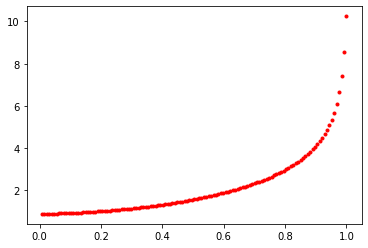

array([ 0.88719922,  0.88943477,  0.89217423,  0.89510004,  0.89811844,
        0.90127337,  0.90479192,  0.90866349,  0.91265044,  0.91684036,
        0.92136525,  0.92611246,  0.93109805,  0.93630338,  0.9418097 ,
        0.94757766,  0.95351824,  0.95978665,  0.96631296,  0.97305321,
        0.9800819 ,  0.98740768,  0.99497206,  1.00278522,  1.01089506,
        1.01928936,  1.027948  ,  1.03688831,  1.04612222,  1.05563416,
        1.06542103,  1.07551394,  1.08591678,  1.09661104,  1.10759869,
        1.11889257,  1.13050054,  1.14242582,  1.15466824,  1.16722955,
        1.18011994,  1.19333416,  1.2068854 ,  1.22078663,  1.23502892,
        1.24961377,  1.26454753,  1.27983918,  1.2955164 ,  1.31156217,
        1.32797667,  1.34476916,  1.36195305,  1.37955867,  1.39755864,
        1.41593114,  1.43473518,  1.45399141,  1.47372573,  1.49389866,
        1.51443248,  1.53541906,  1.55693017,  1.5789898 ,  1.6015724 ,
        1.62458917,  1.64804761,  1.67205168,  1.69668539,  1.72

In [121]:
import booz_xform as bx
b = bx.Booz_xform()
b.read_wout("ARC/VMEC_input_outputs/wout_ARCV2B_13Jun2024.nc")
plt.plot(abs(b.phi[1:]/b.phi[-1]),1/abs(b.iota),'.r')
plt.show()
1/abs(b.iota)

/tmp/ipykernel_2207968/4027139744.py:7: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = np.array(pd.read_csv(file_path, delim_whitespace=True, names=column_names, skiprows=1))


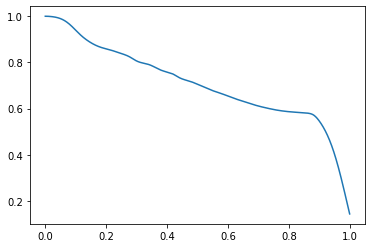

In [213]:
file_path = "ARC/profiles.dat"

#column_names = ['r', 'dnnbi(m^-3)', 'dne(m^-3)', 'dni(m^-3)', 'tbn(keV)', 'ti(keV)', 'te(keV)', 'vzt_eq(m/s)', 'vth_eq(m/s)', 'vthermalep(m/s)', 'etann(MKS)']
column_names = ['r', 'dnnbi', 'dne', 'dni', 'tbn', 'ti', 'te', 'vfova', 'cureq', 'feq', 'pressure', 'iota', 'q', '1/D', 'curvature', 'shear', 'eta']


data = np.array(pd.read_csv(file_path, delim_whitespace=True, names=column_names, skiprows=1))

plt.plot(data[:,0],data[:,3],'-')
plt.show()

/tmp/ipykernel_2207968/4167284989.py:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(file_path, delim_whitespace=True, skiprows=1, header=None)


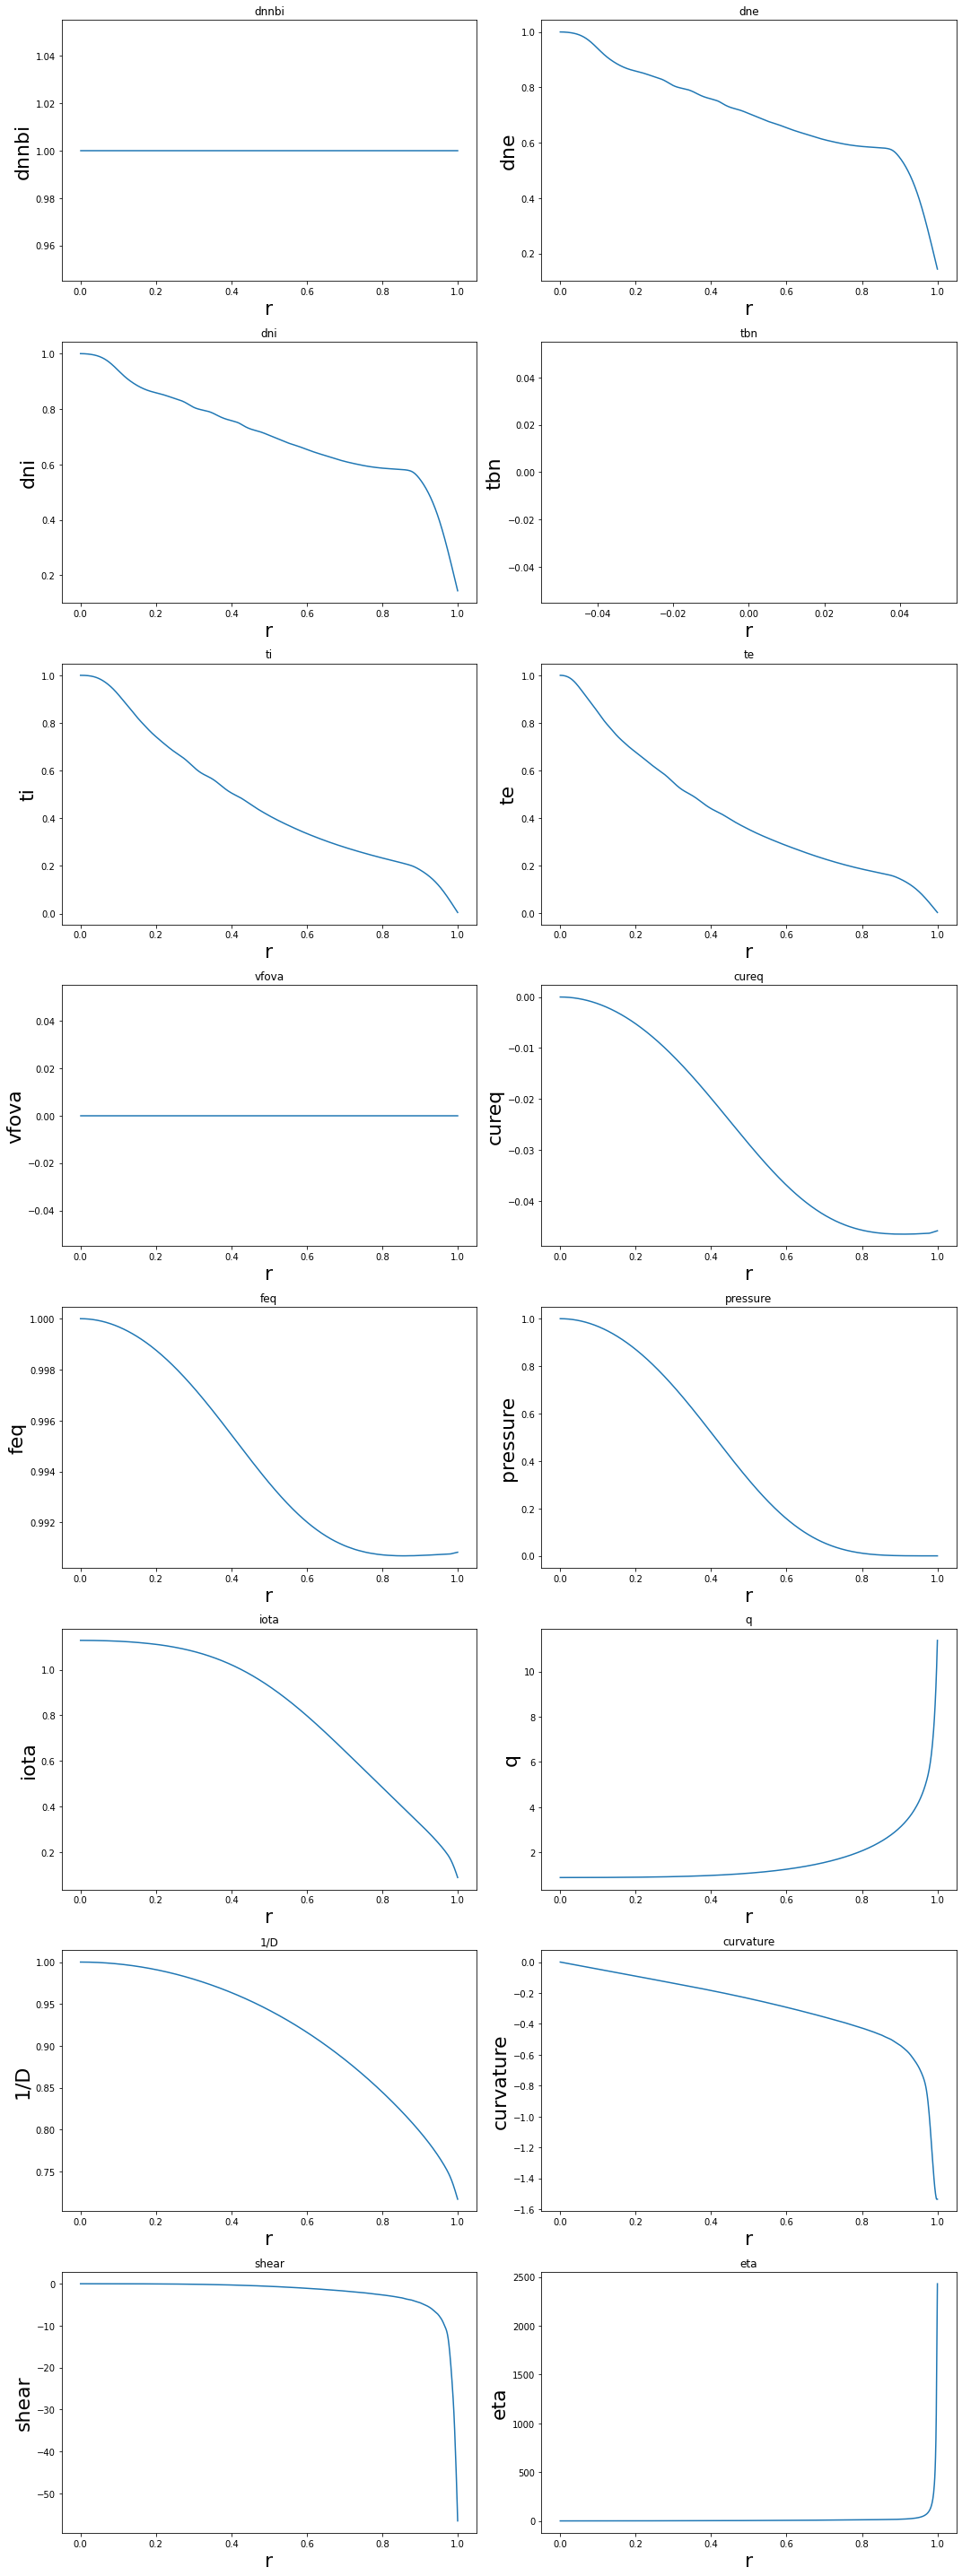

/tmp/ipykernel_2207968/4167284989.py:2: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data = pd.read_csv(file_path, delim_whitespace=True, skiprows=1, header=None)


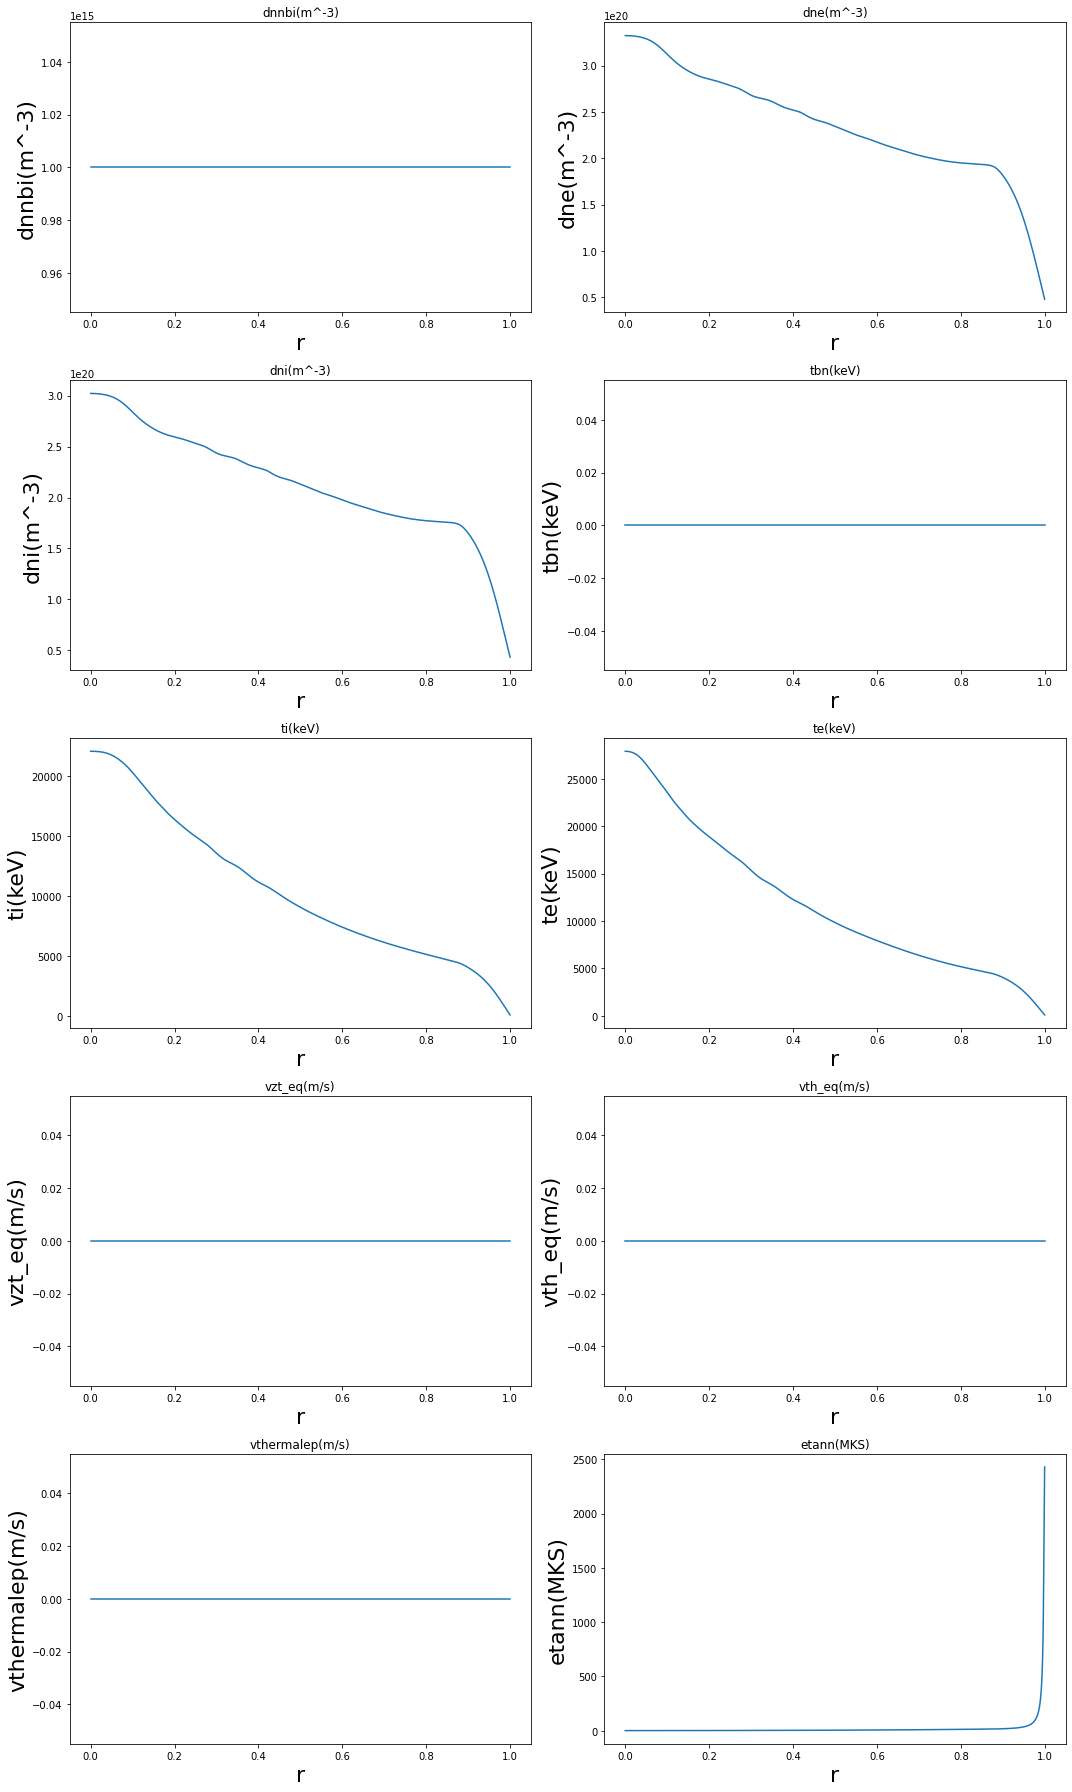

In [230]:
def plot_profiles(file_path):
    data = pd.read_csv(file_path, delim_whitespace=True, skiprows=1, header=None)
    with open(file_path, 'r') as file:
        first_row = file.readline().strip().split()
        data.columns = first_row
        
    num_columns = len(data.columns) - 1
    num_rows = (num_columns + 1) // 2
    fig, axes = plt.subplots(nrows=num_rows, ncols=2, figsize=(15, 5 * num_rows))
    axes = axes.flatten()
    for i, column in enumerate(data.columns[1:]):
        axes[i].plot(data['r'].to_numpy(), data[column].to_numpy())
        axes[i].set_title(column)
        axes[i].set_xlabel('r')
        axes[i].set_ylabel(column)
    
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.show()

plot_profiles("ARC2/profiles.dat")
plot_profiles("ARC2/profiles_ex.dat")
# dnnbi = energetic particle density, dni = thermal ion density 
